# Student Performance Prediction Using Machine Learning

In [2]:
# 1. Importing the Libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [3]:
# 2. Loading the Dataset

df = pd.read_csv("C:\\Users\\HP\\Documents\\Student_Performance.csv")

df


,Study_Hours,Attendance,Previous_Marks,Assignment_Score,Sleep_Hours,Participation,Subject_Average,Result
0,6.4,89,62,71,5.4,74,77.3,Pass
1,4.1,84,41,65,5.3,62,56.7,Pass
2,7.0,74,38,69,4.9,79,60.9,Pass
3,5.9,94,46,65,7.1,73,59.4,Pass
4,1.7,47,68,56,8.4,41,48.8,Fail
...,...,...,...,...,...,...,...,...
495,4.8,66,20,40,6.7,59,40.5,Fail
496,4.0,73,64,72,6.7,49,59.2,Fail
497,5.4,87,100,100,6.1,64,90.0,Pass
498,3.5,68,42,54,7.6,50,39.6,Fail


In [4]:

# 3. Inspecting the Dataset

print(df.shape)

df.head()


(500, 8)


,Study_Hours,Attendance,Previous_Marks,Assignment_Score,Sleep_Hours,Participation,Subject_Average,Result
0,6.4,89,62,71,5.4,74,77.3,Pass
1,4.1,84,41,65,5.3,62,56.7,Pass
2,7.0,74,38,69,4.9,79,60.9,Pass
3,5.9,94,46,65,7.1,73,59.4,Pass
4,1.7,47,68,56,8.4,41,48.8,Fail


In [5]:
# 4. Checking Dataset Information

df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Study_Hours       500 non-null    float64
 1   Attendance        500 non-null    int64  
 2   Previous_Marks    500 non-null    int64  
 3   Assignment_Score  500 non-null    int64  
 4   Sleep_Hours       500 non-null    float64
 5   Participation     500 non-null    int64  
 6   Subject_Average   500 non-null    float64
 7   Result            500 non-null    object 
dtypes: float64(3), int64(4), object(1)
memory usage: 31.4+ KB


In [6]:
# 5. Checking Missing Values

df.isnull().sum()


Study_Hours         0
Attendance          0
Previous_Marks      0
Assignment_Score    0
Sleep_Hours         0
Participation       0
Subject_Average     0
Result              0
dtype: int64

In [7]:
# 6. Checking Duplicate Records

df.duplicated().sum()


np.int64(0)

In [8]:
# 7. Checking Target Variable Distribution

df["Result"].value_counts()


Result
Pass    282
Fail    218
Name: count, dtype: int64

In [9]:
# 8. Separating Features and Target

X = df.drop("Result", axis=1)
y = df["Result"]

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)


Features Shape: (500, 7)
Target Shape: (500,)


In [10]:
# 9. Encoding the Target Variable

y = y.map({"Fail": 0, "Pass": 1})

print(y.value_counts())


Result
1    282
0    218
Name: count, dtype: int64


In [11]:

# 10. Splitting the Dataset

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("X_train Shape:", X_train.shape)
print("X_test Shape:", X_test.shape)
print("y_train Shape:", y_train.shape)
print("y_test Shape:", y_test.shape)


X_train Shape: (400, 7)
X_test Shape: (100, 7)
y_train Shape: (400,)
y_test Shape: (100,)


In [12]:
# 11. Scaling the Features

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training Data Shape:", X_train_scaled.shape)
print("Testing Data Shape:", X_test_scaled.shape)


Training Data Shape: (400, 7)
Testing Data Shape: (100, 7)


In [13]:
# 12. Training the Machine Learning Model

from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000)

model.fit(X_train_scaled, y_train)

print("Model Training Completed")


Model Training Completed


In [14]:
# 13. Making Predictions

y_pred = model.predict(X_test_scaled)

print(y_pred)


[1 1 1 0 0 1 0 1 1 1 1 0 0 0 1 0 1 0 1 0 1 1 0 0 1 1 1 1 0 1 1 1 1 1 1 1 0
 0 0 1 1 1 1 1 0 0 0 0 0 0 1 1 0 1 0 1 1 1 0 0 1 1 1 0 0 0 1 1 0 0 1 1 1 1
 1 1 1 1 0 1 0 0 1 1 0 1 0 1 1 1 0 1 1 0 0 1 0 1 1 1]


In [15]:
# 14. Evaluating Model Accuracy

from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", accuracy)
print("Model Accuracy (%):", accuracy * 100)


Model Accuracy: 0.91
Model Accuracy (%): 91.0


In [16]:
# 15. Evaluating Model Using Confusion Matrix

from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

print(cm)



[[37  7]
 [ 2 54]]


In [17]:
# 16. Classification Report

from sklearn.metrics import classification_report

print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["Fail", "Pass"]
))


              precision    recall  f1-score   support

        Fail       0.95      0.84      0.89        44
        Pass       0.89      0.96      0.92        56

    accuracy                           0.91       100
   macro avg       0.92      0.90      0.91       100
weighted avg       0.91      0.91      0.91       100



In [18]:
# 17. Predicting a New Student's Result

new_student = pd.DataFrame({
    "Study_Hours": [6],
    "Attendance": [85],
    "Previous_Marks": [75],
    "Assignment_Score": [80],
    "Sleep_Hours": [7],
    "Participation": [70],
    "Subject_Average": [78]
})

new_student_scaled = scaler.transform(new_student)

prediction = model.predict(new_student_scaled)

if prediction[0] == 1:
    print("Predicted Result: Pass")
else:
    print("Predicted Result: Fail")


Predicted Result: Pass


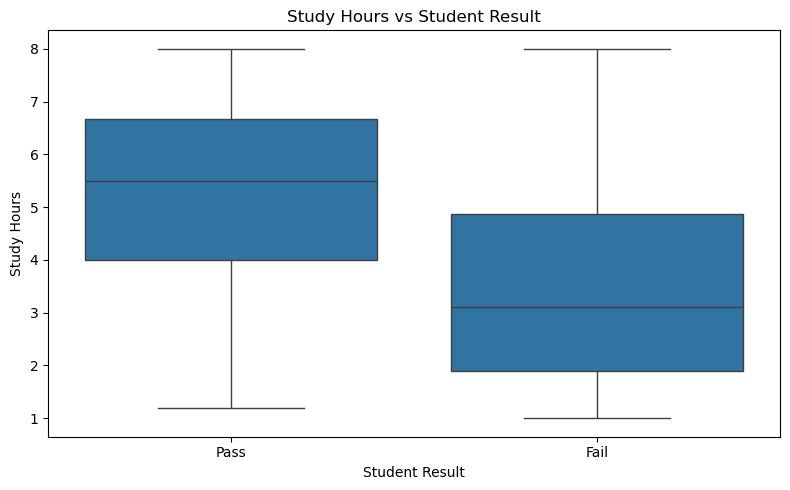

In [19]:
# 18. Visualizing Study Hours and Student Results

plt.figure(figsize=(8, 5))

sns.boxplot(data=df, x="Result", y="Study_Hours")

plt.title("Study Hours vs Student Result")
plt.xlabel("Student Result")
plt.ylabel("Study Hours")

plt.tight_layout()
plt.show()
